In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt

In [2]:
!pip install lifetimes
!pip install plotly

In [3]:
df1 = pd.read_csv("./online_retail_II(2).csv", encoding="latin1")
df2 = pd.read_csv("./online_retail_II.csv" , encoding="latin1")
df = pd.concat([df1,df2])

In [4]:
df

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
...,...,...,...,...,...,...,...,...
525456,538171,22271,FELTCRAFT DOLL ROSIE,2,12/9/2010 20:01,2.95,17530.0,United Kingdom
525457,538171,22750,FELTCRAFT PRINCESS LOLA DOLL,1,12/9/2010 20:01,3.75,17530.0,United Kingdom
525458,538171,22751,FELTCRAFT PRINCESS OLIVIA DOLL,1,12/9/2010 20:01,3.75,17530.0,United Kingdom
525459,538171,20970,PINK FLORAL FELTCRAFT SHOULDER BAG,2,12/9/2010 20:01,3.75,17530.0,United Kingdom


In [5]:
df.describe()

,Quantity,Price,Customer ID
count,1.067371e+06,1.067371e+06,824364.000000
mean,9.938898e+00,4.649388e+00,15324.638504
std,1.727058e+02,1.235531e+02,1697.464450
min,-8.099500e+04,-5.359436e+04,12346.000000
25%,1.000000e+00,1.250000e+00,13975.000000
50%,3.000000e+00,2.100000e+00,15255.000000
75%,1.000000e+01,4.150000e+00,16797.000000
max,8.099500e+04,3.897000e+04,18287.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1067371 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 73.3+ MB


In [7]:
# 1. Drop rows with missing Customer ID
df.dropna(subset=['Customer ID'], inplace=True)
df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[df['Quantity'] > 0]
df['Customer ID'] = df['Customer ID'].astype(int)
df['TotalPrice'] = df['Quantity'] * df['Price']
print("Data cleaned and preprocessed.")
print("New shape of the dataframe:", df.shape)

Data cleaned and preprocessed.
New shape of the dataframe: (805620, 9)


In [8]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%Y %H:%M")

In [9]:
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)
print(f"Snapshot Date: {snapshot_date}")

Snapshot Date: 2011-12-10 12:50:00


In [10]:
df.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country', 'TotalPrice'],
      dtype='object')

In [11]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%d-%m-%Y %H:%M")
df['first_purchase_date'] = df.groupby('Customer ID')['InvoiceDate'].transform('min')
df['customer_type'] = np.where(df['InvoiceDate'] == df['first_purchase_date'], 'New', 'Returning')
df['month'] = df['InvoiceDate'].dt.to_period('M')

monthly_revenue_by_type = (
    df.groupby(['month', 'customer_type'])['TotalPrice']
      .sum()
      .unstack(fill_value=0)
      .reset_index()
)

In [12]:
monthly_revenue_by_type

customer_type,month,New,Returning
0,2009-12,402307.950,284346.210
1,2010-01,147170.741,410148.321
2,2010-02,148648.304,357722.762
3,2010-03,196291.841,503317.150
4,2010-04,118740.351,475868.841
5,2010-05,102542.760,497443.030
6,2010-06,117489.320,521577.260
7,2010-07,59663.790,531972.950
8,2010-08,53480.310,550762.340
9,2010-09,145809.170,685805.831


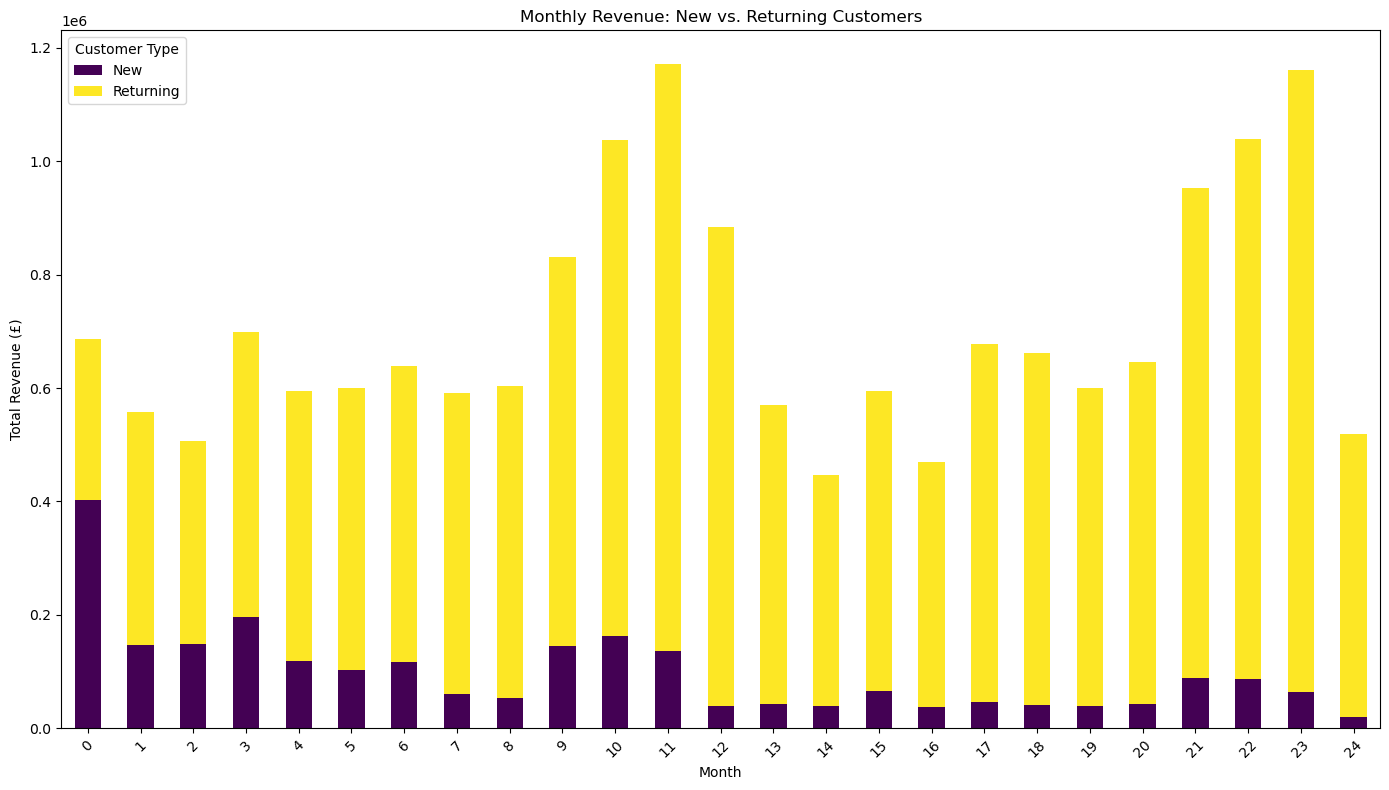

In [14]:
monthly_revenue_by_type.plot(
    kind='bar', 
    stacked=True, 
    figsize=(14, 8),
    colormap='viridis',
    title='Monthly Revenue: New vs. Returning Customers'
)
plt.xlabel('Month')
plt.ylabel('Total Revenue (£)')
plt.xticks(rotation=45)
plt.legend(title='Customer Type')
plt.tight_layout()
plt.show()

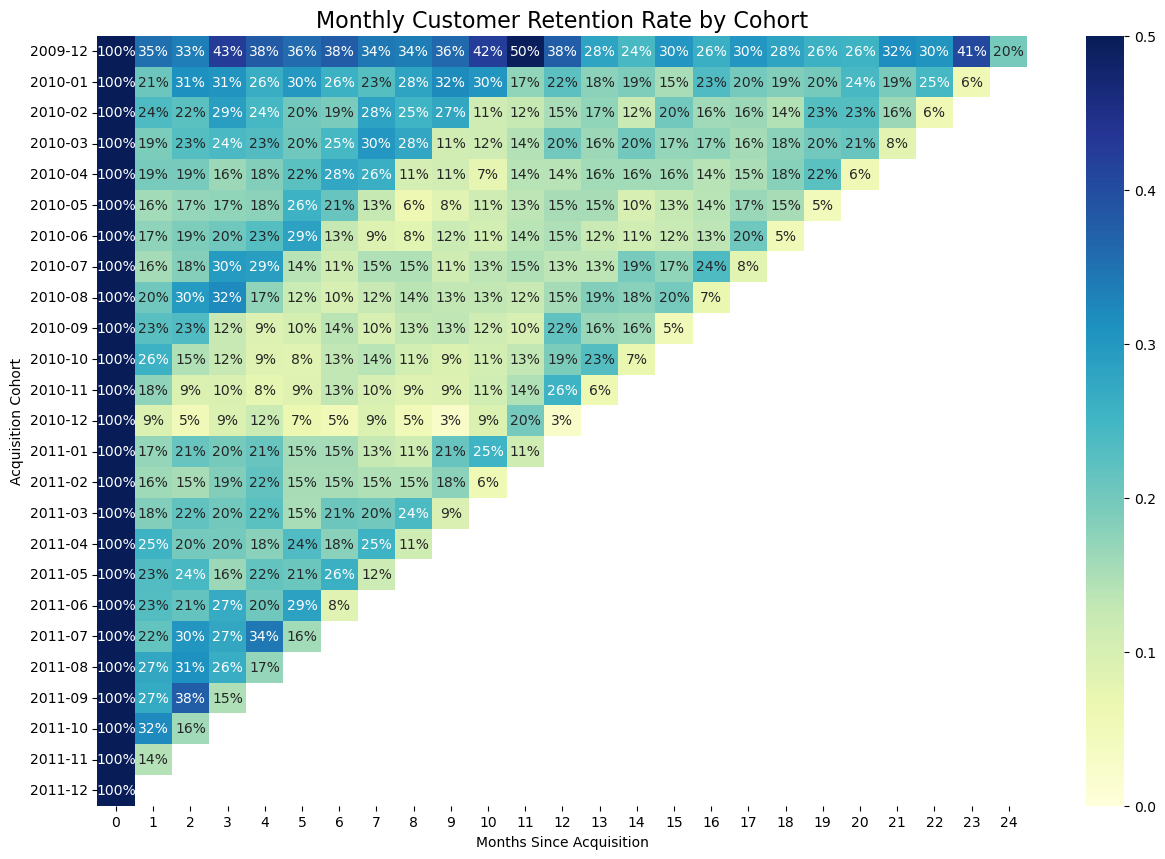

In [15]:
df['cohort'] = df.groupby('Customer ID')['InvoiceDate'].transform('min').dt.to_period('M')

# 2. Calculate the month of each transaction
df['order_month'] = df['InvoiceDate'].dt.to_period('M')

# 3. Calculate the cohort index (number of months since acquisition)
def get_cohort_index(df, event_col, cohort_col):
    year_diff = df[event_col].dt.year - df[cohort_col].dt.year
    month_diff = df[event_col].dt.month - df[cohort_col].dt.month
    return year_diff * 12 + month_diff

df['cohort_index'] = get_cohort_index(df, 'order_month', 'cohort')

# 4. Create the cohort data pivot table
cohort_data = df.groupby(['cohort', 'cohort_index'])['Customer ID'].nunique().reset_index()
cohort_counts = cohort_data.pivot_table(index='cohort', columns='cohort_index', values='Customer ID')
cohort_size = cohort_counts.iloc[:,0]
retention = cohort_counts.divide(cohort_size, axis=0)
retention.index = retention.index.strftime('%Y-%m')
plt.figure(figsize=(15, 10))
sns.heatmap(
    retention,
    annot=True,
    fmt='.0%', # Format as percentage
    cmap='YlGnBu',
    vmin=0.0,
    vmax=0.5 # Adjust vmax to see color variations better
)

plt.title('Monthly Customer Retention Rate by Cohort', fontsize=16)
plt.xlabel('Months Since Acquisition')
plt.ylabel('Acquisition Cohort')
plt.show()

C:\Users\karth\AppData\Local\Temp\ipykernel_25844\1855076634.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxenplot(y='TotalPrice', data=capped_df, palette='magma')


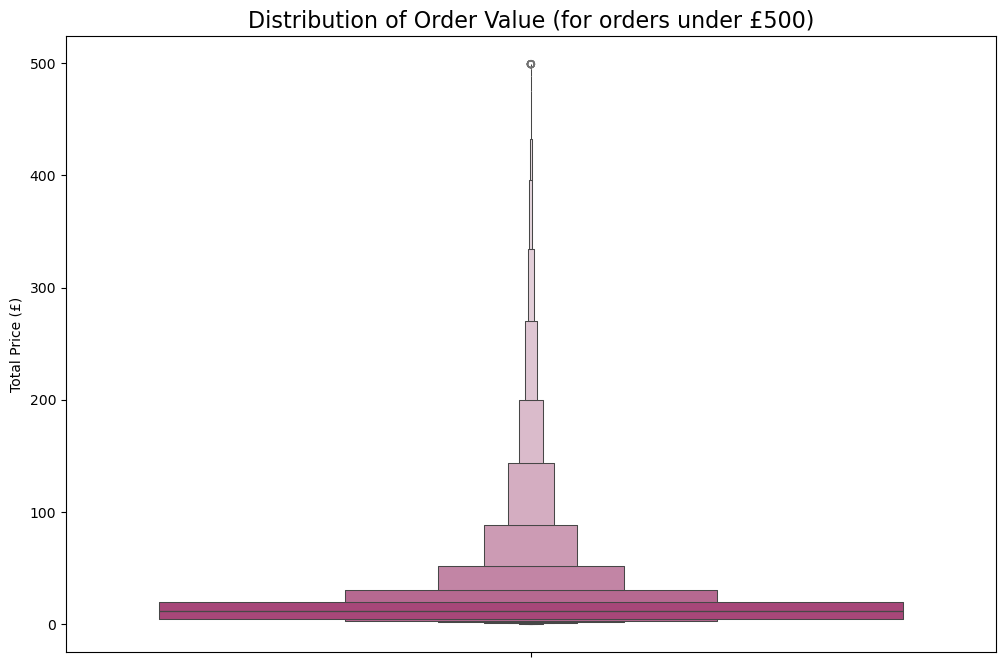

In [16]:
capped_df = df[df['TotalPrice'] < 500]

plt.figure(figsize=(12, 8))
sns.boxenplot(y='TotalPrice', data=capped_df, palette='magma')
plt.title('Distribution of Order Value (for orders under £500)', fontsize=16)
plt.ylabel('Total Price (£)')
plt.show()

In [17]:
# We'll need the lifetimes library and the pre-merged/cleaned dataframe from the EDA
from lifetimes import BetaGeoFitter, GammaGammaFitter
from lifetimes.utils import summary_data_from_transaction_data


lifetimes_df = df[['Customer ID', 'InvoiceDate', 'TotalPrice']]
lifetimes_df.columns = ['customer_id', 'date', 'monetary_value']
lifetimes_df['date'] = pd.to_datetime(lifetimes_df['date'])

# Generate the summary data required by lifetimes
summary = summary_data_from_transaction_data(
    lifetimes_df,
    customer_id_col='customer_id',
    datetime_col='date',
    monetary_value_col='monetary_value',
)

print("Lifetimes summary data created. Here's a sample:")
print(summary.head())

Lifetimes summary data created. Here's a sample:
             frequency  recency      T  monetary_value
customer_id                                           
12346              7.0    400.0  725.0    11066.637143
12347              7.0    402.0  404.0      717.398571
12348              4.0    363.0  438.0      449.310000
12349              3.0    571.0  589.0     1120.056667
12350              0.0      0.0  310.0        0.000000


In [18]:
# Instantiate and fit the BetaGeoFitter model
bgf = BetaGeoFitter(penalizer_coef=0.0)
bgf.fit(summary['frequency'], summary['recency'], summary['T'])

print("\nBG/NBD Model training complete.")
print(bgf.summary)


BG/NBD Model training complete.
            coef  se(coef)  lower 95% bound  upper 95% bound
r       0.662732  0.015825         0.631715         0.693749
alpha  63.184460  1.934702        59.392443        66.976476
a       0.108660  0.015446         0.078387         0.138934
b       2.418366  0.524988         1.389391         3.447342


In [19]:
# Filter the summary data for customers with frequency > 0
ggf_summary = summary[summary['frequency'] > 0]

# Instantiate and fit the GammaGammaFitter model
ggf = GammaGammaFitter(penalizer_coef=0.0)
ggf.fit(ggf_summary['frequency'], ggf_summary['monetary_value'])

print("\nGamma-Gamma Model training complete.")
print(ggf.summary)


Gamma-Gamma Model training complete.
         coef   se(coef)  lower 95% bound  upper 95% bound
p    2.130608   0.104812         1.925176         2.336040
q    3.530916   0.112395         3.310621         3.751210
v  486.532804  37.150445       413.717931       559.347677


In [20]:
# Define the prediction horizon in months
prediction_months = 6

# Calculate the CLV
summary['predicted_clv'] = ggf.customer_lifetime_value(
    bgf,
    summary['frequency'],
    summary['recency'],
    summary['T'],
    summary['monetary_value'],
    time=prediction_months,  # time in months
    discount_rate=0.01      # monthly discount rate
)

# --- Let's see the results! ---
# Sort customers by their predicted value
top_customers = summary.sort_values(by='predicted_clv', ascending=False)

print(f"\nTop 10 Customers by Predicted CLV over the next {prediction_months} months:")
print(top_customers.head(10))

# What is the total predicted revenue for the next 6 months?
total_predicted_revenue = top_customers['predicted_clv'].sum()
print(f"\nTotal predicted revenue for the next {prediction_months} months: R${total_predicted_revenue:,.2f}")


Top 10 Customers by Predicted CLV over the next 6 months:
             frequency  recency      T  monetary_value  predicted_clv
customer_id                                                          
18102             66.0    738.0  738.0     9189.930455  129045.891072
14646             90.0    736.0  737.0     5809.905333  111660.140530
16446              1.0    205.0  205.0   168469.600000   77829.954281
17450             30.0    430.0  438.0     6924.523000   69434.046961
14156            120.0    729.0  738.0     2607.329750   66722.329886
14096             16.0     97.0  101.0     4071.434375   63948.609962
14911            254.0    737.0  738.0     1162.358268   63291.454168
13694             82.0    732.0  735.0     2365.279512   41544.242157
12415             22.0    503.0  527.0     6460.528636   39998.393673
17511             50.0    735.0  737.0     3449.898200   36701.328969

Total predicted revenue for the next 6 months: R$4,532,551.33


In [21]:
# Move index (customer_id) back into a column
summary = summary.reset_index()

(summary.head())

,customer_id,frequency,recency,T,monetary_value,predicted_clv
0,12346,7.0,400.0,725.0,11066.637143,9056.096707
1,12347,7.0,402.0,404.0,717.398571,1861.450659
2,12348,4.0,363.0,438.0,449.310000,672.597361
3,12349,3.0,571.0,589.0,1120.056667,863.017724
4,12350,0.0,0.0,310.0,0.000000,124.544927


In [22]:
tier_labels = ["Low-Tier" , "Mid-Tier-1" , "Mid-Tier-2" , "Top-Tier"]
summary["CLV_Tier"] = pd.qcut(summary["predicted_clv"] , q=4 , labels=tier_labels,duplicates="drop")
summary['CLV_Tier'] = summary['CLV_Tier'].replace(['Mid-Tier-1', 'Mid-Tier-2'], 'Mid-Tier')

In [23]:
print("Distribution of customers across CLV Tiers:")
print(summary['CLV_Tier'].value_counts())

# 3. Analyze the average predicted CLV for each tier
print("\nAverage Predicted CLV per Tier:")
print(summary.groupby('CLV_Tier')['predicted_clv'].mean())

# Let's see the result in the DataFrame
print("\nDataFrame with CLV Tiers:")
print(summary.sort_values(by='predicted_clv', ascending=False).head())

Distribution of customers across CLV Tiers:
CLV_Tier
Mid-Tier    2942
Low-Tier    1471
Top-Tier    1468
Name: count, dtype: int64

Average Predicted CLV per Tier:
CLV_Tier
Low-Tier      82.339657
Mid-Tier     327.356042
Top-Tier    2349.011046
Name: predicted_clv, dtype: float64

DataFrame with CLV Tiers:
      customer_id  frequency  recency      T  monetary_value  predicted_clv  \
5695        18102       66.0    738.0  738.0     9189.930455  129045.891072   
2279        14646       90.0    736.0  737.0     5809.905333  111660.140530   
4064        16446        1.0    205.0  205.0   168469.600000   77829.954281   
5053        17450       30.0    430.0  438.0     6924.523000   69434.046961   
1791        14156      120.0    729.0  738.0     2607.329750   66722.329886   

      CLV_Tier  
5695  Top-Tier  
2279  Top-Tier  
4064  Top-Tier  
5053  Top-Tier  
1791  Top-Tier  


In [24]:
summary.head()

,customer_id,frequency,recency,T,monetary_value,predicted_clv,CLV_Tier
0,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier
1,12347,7.0,402.0,404.0,717.398571,1861.450659,Top-Tier
2,12348,4.0,363.0,438.0,449.310000,672.597361,Top-Tier
3,12349,3.0,571.0,589.0,1120.056667,863.017724,Top-Tier
4,12350,0.0,0.0,310.0,0.000000,124.544927,Mid-Tier


In [25]:
summary.columns=["Customer ID" , "frequency" , "recency" , "T" , "monetary_value" , "predicted_clv"  , "CLV_Tier"]

## Customer Lifetime Value (CLV) Forecasting Summary

### Probabilistic Model (Lifetimes Library)
- A probabilistic model was built using the **lifetimes** library to forecast future customer behavior.

### Key Insights

#### 1. High-Value Customers Identified
- The model successfully identified a cohort of customers with significantly higher predicted CLV.  
- **Top 10 customers** are forecasted to generate between **£36,000 and £129,000** over the next **6 months**.

#### 2. Total Revenue Forecast
- The model predicts a **total revenue of £4.5 million** from the existing customer base over the next **6 months**.  
- This provides a valuable benchmark for **financial planning**.

#### 3. Customer Segmentation into Tiers
Customers were segmented based on their predicted CLV:

- **Top-Tier (Top 25%)**  
  - Average predicted 6-month value: **~£2,349**

- **Mid-Tier (Middle 50%)**  
  - Average predicted 6-month value: **~£327**

- **Low-Tier (Bottom 25%)**  
  - Average predicted 6-month value: **~£82**


In [26]:
merged_country = summary.merge(df[["Customer ID" , "Country"]] , on="Customer ID" , how="left")

In [27]:
merged_country = merged_country.drop_duplicates()

In [28]:
merged_country

,Customer ID,frequency,recency,T,monetary_value,predicted_clv,CLV_Tier,Country
0,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,United Kingdom
34,12347,7.0,402.0,404.0,717.398571,1861.450659,Top-Tier,Iceland
287,12348,4.0,363.0,438.0,449.310000,672.597361,Top-Tier,Finland
338,12349,3.0,571.0,589.0,1120.056667,863.017724,Top-Tier,Italy
513,12350,0.0,0.0,310.0,0.000000,124.544927,Mid-Tier,Norway
...,...,...,...,...,...,...,...,...
804372,18283,18.0,655.0,658.0,146.405556,718.991277,Top-Tier,United Kingdom
805358,18284,0.0,0.0,431.0,0.000000,94.375506,Low-Tier,United Kingdom
805386,18285,0.0,0.0,660.0,0.000000,64.719512,Low-Tier,United Kingdom
805398,18286,1.0,247.0,723.0,833.480000,181.609466,Mid-Tier,United Kingdom


In [29]:
Tier_Geo = (
    merged_country
    .groupby(["CLV_Tier", "Country"])["Country"]
    .size()
    .reset_index(name="count")
)
Tier_Geo

,CLV_Tier,Country,count
0,Low-Tier,Australia,6
1,Low-Tier,Austria,1
2,Low-Tier,Bahrain,0
3,Low-Tier,Belgium,3
4,Low-Tier,Brazil,1
...,...,...,...
118,Top-Tier,USA,1
119,Top-Tier,United Arab Emirates,1
120,Top-Tier,United Kingdom,1285
121,Top-Tier,Unspecified,1


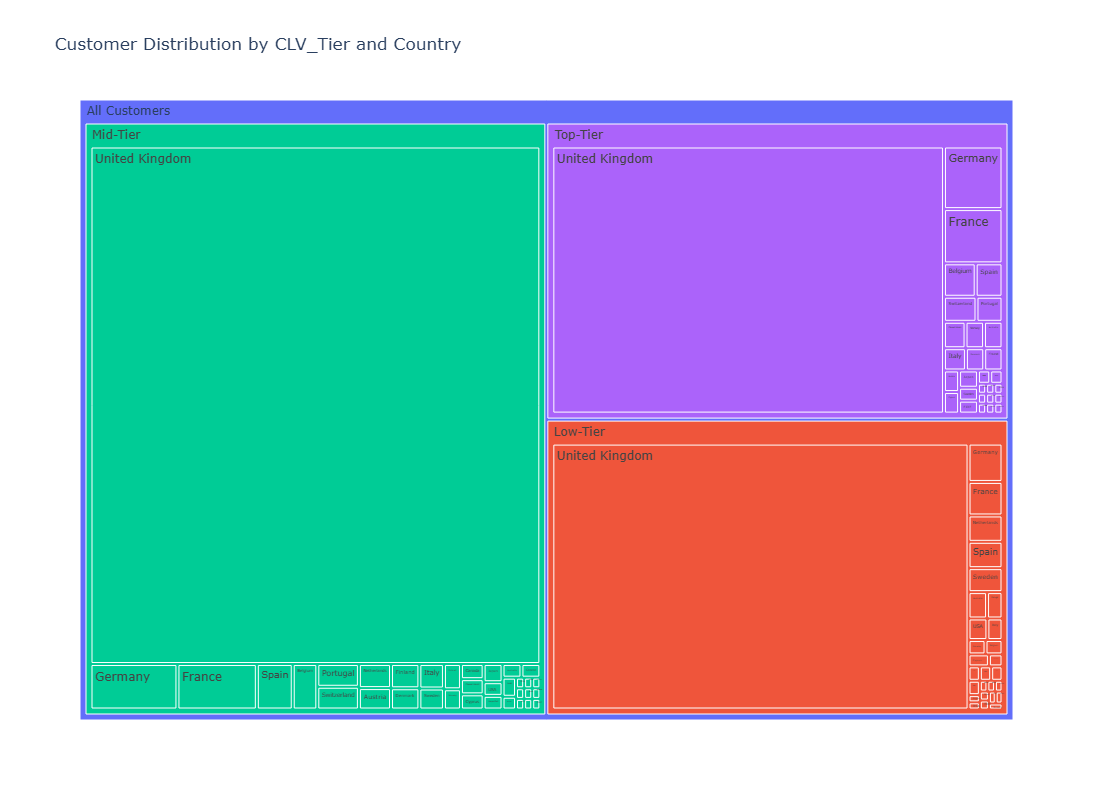

In [30]:
Tier_Geo_plot = Tier_Geo.copy()

Tier_Geo_plot['CLV_Tier'] = Tier_Geo_plot['CLV_Tier'].astype(object)
Tier_Geo_plot['Country'] = Tier_Geo_plot['Country'].astype(object)

import plotly.express as px

fig = px.treemap(
    Tier_Geo_plot,
    path=[px.Constant("All Customers"), 'CLV_Tier', 'Country'], # Defines the hierarchy
    values='count',
    color='CLV_Tier',
    title='Customer Distribution by CLV_Tier and Country',
    width=1000,   # increase width
    height=800    # increase height
)
fig.show()

In [31]:
merged_product = summary.merge(df[["Customer ID" , "Description" , "TotalPrice"]] , on="Customer ID" , how="left")

In [32]:
merged_product

,Customer ID,frequency,recency,T,monetary_value,predicted_clv,CLV_Tier,Description,TotalPrice
0,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,MEDIUM CERAMIC TOP STORAGE JAR,77183.6
1,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,This is a test product.,45.0
2,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,This is a test product.,22.5
3,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,This is a test product.,22.5
4,12346,7.0,400.0,725.0,11066.637143,9056.096707,Top-Tier,This is a test product.,22.5
...,...,...,...,...,...,...,...,...,...
805615,18287,5.0,529.0,571.0,622.276000,869.773684,Top-Tier,HAND WARMER SCOTTY DOG DESIGN,25.2
805616,18287,5.0,529.0,571.0,622.276000,869.773684,Top-Tier,SET/4 RED MINI ROSE CANDLE IN BOWL,69.6
805617,18287,5.0,529.0,571.0,622.276000,869.773684,Top-Tier,S/4 IVORY MINI ROSE CANDLE IN BOWL,69.6
805618,18287,5.0,529.0,571.0,622.276000,869.773684,Top-Tier,S/4 PINK FLOWER CANDLES IN BOWL,69.6


In [33]:
Tier_Product = (
    merged_product
    .groupby(["CLV_Tier", "Description"])["Description"]
    .size()
    .reset_index(name="count")
    .sort_values(by="count", ascending=False)
)

In [51]:
descript_sort = (
    Tier_Product
    .sort_values(by="count", ascending=False)
    .groupby("CLV_Tier")
    .head(5)
)
descript_sort

,CLV_Tier,Description,count
15613,Top-Tier,WHITE HANGING HEART T-LIGHT HOLDER,3129
14335,Top-Tier,REGENCY CAKESTAND 3 TIER,2339
12958,Top-Tier,JUMBO BAG RED RETROSPOT,2091
10858,Top-Tier,ASSORTED COLOUR BIRD ORNAMENT,1788
10330,Mid-Tier,WHITE HANGING HEART T-LIGHT HOLDER,1543
13175,Top-Tier,LUNCH BAG BLACK SKULL.,1519
9052,Mid-Tier,REGENCY CAKESTAND 3 TIER,932
9127,Mid-Tier,REX CASH+CARRY JUMBO SHOPPER,903
5575,Mid-Tier,ASSORTED COLOUR BIRD ORNAMENT,844
7486,Mid-Tier,HEART OF WICKER LARGE,637


C:\Users\karth\anaconda3\Lib\site-packages\seaborn\axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


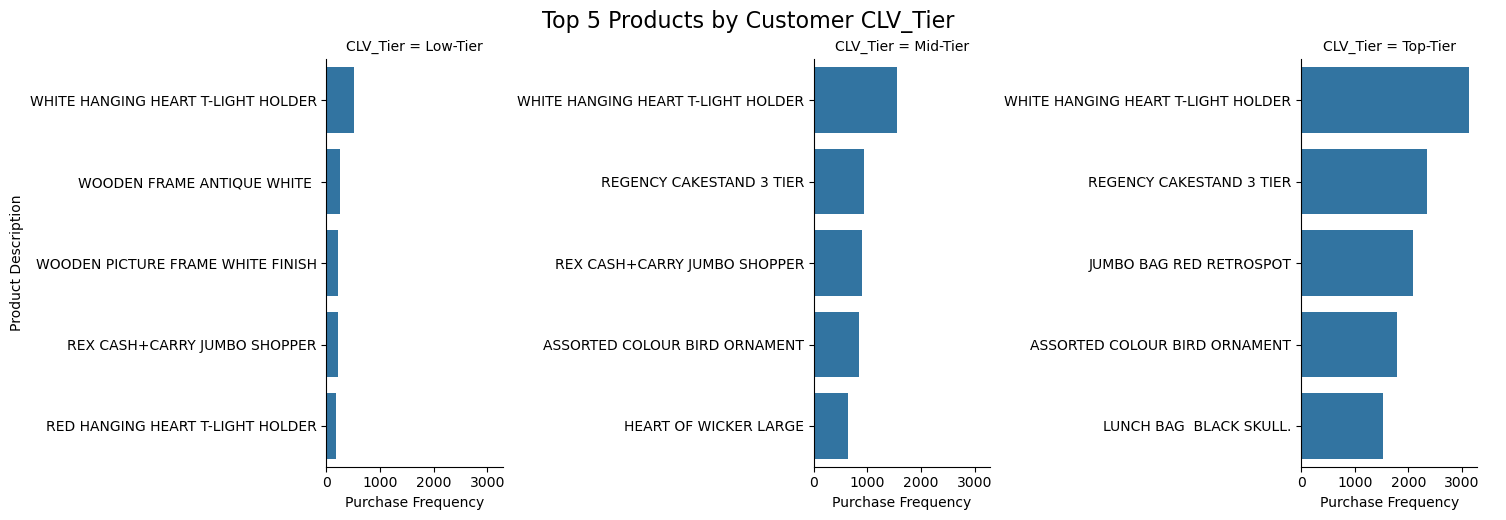

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt



# 1. Create the faceted plot object
g = sns.catplot(
    data=descript_sort,
    y='Description',   # Product names on the vertical axis (better for long labels)
    x='count',         # Counts on the horizontal axis
    col='CLV_Tier',     # This is the key: create a new column of plots for each CLV_Tier
    kind='bar',        # Tell Seaborn you want a bar chart
    sharey=False,      # IMPORTANT: Allows each chart to have its own product labels
    col_wrap=3         # Arrange plots in a grid, wrapping after 3 columns
)

# 2. Add a clear main title
g.fig.suptitle('Top 5 Products by Customer CLV_Tier', y=1.03, fontsize=16)

# 3. Set clear labels for the axes
g.set_axis_labels('Purchase Frequency', 'Product Description')

# 4. Save the final plot to a file
plt.savefig('top_5_products_by_segment_plot.png')

# If you are in a Jupyter Notebook, the plot will also display automatically.

In [36]:
Tier_Cost = (
    merged_product
    .groupby("CLV_Tier")["TotalPrice"]
    .mean()
    .reset_index(name="Avg Price")
)

In [37]:
Tier_Cost

,CLV_Tier,Avg Price
0,Low-Tier,18.006558
1,Mid-Tier,14.474538
2,Top-Tier,25.632431


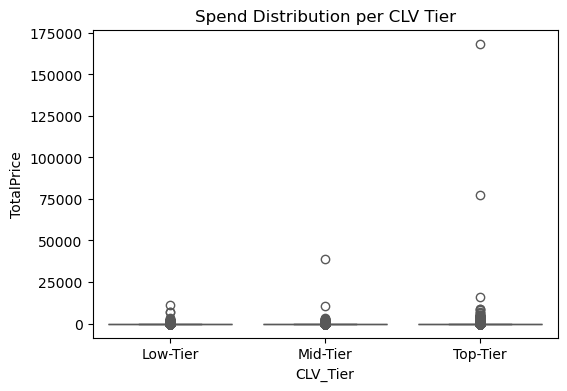

In [38]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.boxplot(x="CLV_Tier", y="TotalPrice", data=merged_product, palette="Set2")
plt.title("Spend Distribution per CLV Tier")
plt.show()

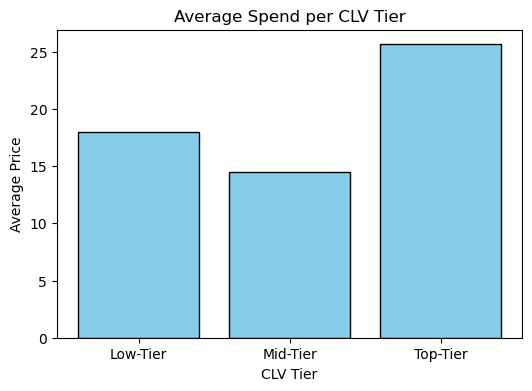

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.bar(Tier_Cost["CLV_Tier"], Tier_Cost["Avg Price"], color="skyblue", edgecolor="black")
plt.title("Average Spend per CLV Tier")
plt.xlabel("CLV Tier")
plt.ylabel("Average Price")
plt.show()

## Customer Profiling Insights

By merging the CLV predictions back with transactional data, a clear profile of the most valuable customers emerged.

### Geographic Hotspot
- The **United Kingdom** is not only the largest market but also overwhelmingly the home of the most valuable **Top-Tier customers**.

### Product Preferences
- Distinct differences exist in purchasing behavior between tiers:
  - **Low-Value Customers**: Tend to buy a wide variety of goods.
  - **Top-Tier Customers**: Show a strong preference for **specific, potentially higher-margin categories**.  
    - *Example (from charts):* **"REGENCY CAKESTAND 3 TIER"**

### Strategic Implications
- **Focus marketing efforts** on promoting **high-value product categories** to **Mid-Tier customers**, especially those located in the **UK**.  
- This strategy could help **nurture Mid-Tier customers into Top-Tier status**, maximizing long-term revenue growth.


In [40]:
end_date = df["InvoiceDate"].max()
split_date = end_date-pd.DateOffset(months=3)

In [41]:
calibration_df = df[df["InvoiceDate"] <= split_date]
holdout_df = df[df["InvoiceDate"] > split_date]

In [42]:
print(f"Data ranges from {df['InvoiceDate'].min()} to {end_date}")
print(f"Calibration data runs up to: {split_date}")
print(f"Holdout data starts from: {split_date + pd.DateOffset(days=1)}")

Data ranges from 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Calibration data runs up to: 2011-09-09 12:50:00
Holdout data starts from: 2011-09-10 12:50:00


In [43]:
# Calculate the total spend for each customer in the holdout period
holdout_target = holdout_df.groupby('Customer ID')['TotalPrice'].sum().reset_index()
holdout_target.columns = ['Customer ID', 'actual_spend_holdout']

print("Target variable 'y' created. Sample:")
print(holdout_target.head())

Target variable 'y' created. Sample:
   Customer ID  actual_spend_holdout
0        12347               1519.14
1        12348                310.00
2        12349               1757.55
3        12352                944.23
4        12356                 58.35


In [44]:
# We will create a summary dataframe from the calibration period
features_df = summary_data_from_transaction_data(
    calibration_df,
    customer_id_col='Customer ID',
    datetime_col='InvoiceDate',
    monetary_value_col='TotalPrice',
    observation_period_end=split_date
)

def avg_days_between(dates):
    dates = np.array(dates)
    if len(dates) > 1:
        return (dates.max() - dates.min()).days / (len(dates) - 1)
    return 0

customer_dates = calibration_df.groupby('Customer ID')['InvoiceDate'].apply(list)
features_df['avg_days_between_purchases'] = customer_dates.apply(avg_days_between)
features_df = features_df.reset_index()
# Standard deviation of purchase values
std= calibration_df.groupby('Customer ID')['TotalPrice'].std().fillna(0).reset_index(name="std_spend")
features_df = features_df.merge(std , on="Customer ID" , how="left")
final_df = pd.merge(features_df, holdout_target, on='Customer ID', how='left')
final_df['actual_spend_holdout'].fillna(0, inplace=True)

In [45]:
final_df.isna().sum()

Customer ID                   0
frequency                     0
recency                       0
T                             0
monetary_value                0
avg_days_between_purchases    0
std_spend                     0
actual_spend_holdout          0
dtype: int64

In [46]:
final_df

,Customer ID,frequency,recency,T,monetary_value,avg_days_between_purchases,std_spend,actual_spend_holdout
0,12346,7.0,400.0,634.0,11066.637143,12.121212,13234.943418,0.00
1,12347,5.0,275.0,313.0,700.530000,1.412371,20.977305,1519.14
2,12348,3.0,190.0,347.0,495.746667,4.021277,40.813755,310.00
3,12349,2.0,182.0,498.0,801.310000,1.792079,33.250740,1757.55
4,12350,0.0,0.0,219.0,0.000000,0.000000,7.275538,0.00
...,...,...,...,...,...,...,...,...
5276,18283,13.0,563.0,567.0,127.776154,0.831361,2.205076,974.21
5277,18284,0.0,0.0,340.0,0.000000,0.000000,9.580762,0.00
5278,18285,0.0,0.0,569.0,0.000000,0.000000,54.485692,0.00
5279,18286,1.0,247.0,632.0,833.480000,3.742424,11.524210,0.00


In [47]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Prepare data for XGBoost
X = final_df.drop(['Customer ID', 'actual_spend_holdout'], axis=1)
y = final_df['actual_spend_holdout']

# Although we have a holdout, we can still use a validation set for early stopping
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate and train the model
xgb = XGBRegressor(n_estimators=1000, learning_rate=0.05, early_stopping_rounds=10, random_state=42)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

# Make predictions on the entire dataset
final_df['xgb_prediction'] = xgb.predict(X)

print("\nXGBoost model trained and predictions made.")


XGBoost model trained and predictions made.


In [48]:
# 1. Fit the lifetimes models ONLY on the calibration data
bgf_calib = BetaGeoFitter(penalizer_coef=0.0)
bgf_calib.fit(features_df['frequency'], features_df['recency'], features_df['T'])

ggf_calib = GammaGammaFitter(penalizer_coef=0.0)
ggf_calib.fit(features_df[features_df['frequency']>0]['frequency'], 
              features_df[features_df['frequency']>0]['monetary_value'])

# 2. Predict spend for the holdout period (3 months)
final_df['lifetimes_prediction'] = ggf_calib.customer_lifetime_value(
    bgf_calib,
    features_df['frequency'],
    features_df['recency'],
    features_df['T'],
    features_df['monetary_value'],
    time=3, # 3 months holdout period
    discount_rate=0.01
)

# --- Compare the Errors ---
# XGBoost Evaluation
xgb_rmse = np.sqrt(mean_squared_error(final_df['actual_spend_holdout'], final_df['xgb_prediction']))
xgb_mae = mean_absolute_error(final_df['actual_spend_holdout'], final_df['xgb_prediction'])

# Lifetimes Evaluation
lifetimes_rmse = np.sqrt(mean_squared_error(final_df['actual_spend_holdout'], final_df['lifetimes_prediction']))
lifetimes_mae = mean_absolute_error(final_df['actual_spend_holdout'], final_df['lifetimes_prediction'])

print("\n--- Model Comparison ---")
print(f"XGBoost Model RMSE: {xgb_rmse:.2f}")
print(f"XGBoost Model MAE:  {xgb_mae:.2f}")
print("-" * 20)
print(f"Lifetimes Model RMSE: {lifetimes_rmse:.2f}")
print(f"Lifetimes Model MAE:  {lifetimes_mae:.2f}")


--- Model Comparison ---
XGBoost Model RMSE: 2640.63
XGBoost Model MAE:  364.01
--------------------
Lifetimes Model RMSE: 3182.28
Lifetimes Model MAE:  434.57


In [49]:
# Assuming 'final_df' is your dataframe with 'actual_spend_holdout'

# Average spend across ALL customers (including non-spenders)
mean_spend_all = final_df['actual_spend_holdout'].mean()

# Average spend for ONLY customers who made a purchase in the holdout
mean_spend_buyers = final_df[final_df['actual_spend_holdout'] > 0]['actual_spend_holdout'].mean()

print(f"The MAE of the XGBoost model is: R${xgb_mae:,.2f}")
print("-" * 30)
print(f"The average spend across ALL customers was: R${mean_spend_all:,.2f}")
print(f"The average spend for customers WHO BOUGHT was: R${mean_spend_buyers:,.2f}")

The MAE of the XGBoost model is: R$364.01
------------------------------
The average spend across ALL customers was: R$580.08
The average spend for customers WHO BOUGHT was: R$1,335.40


## Model Comparison: Probabilistic vs. Machine Learning

A second, more traditional machine learning model (**XGBoost**) was built to predict future spend and its performance was compared against the **lifetimes** model.

### Key Findings

#### 1. XGBoost is More Accurate for Tactical Forecasting
- **XGBoost** achieved lower prediction errors:
  - RMSE: ~2640 (vs. ~3182 for lifetimes)
  - MAE: ~364 (vs. ~434 for lifetimes)  
- This makes XGBoost the superior tool for generating the most **accurate short-term financial forecasts** for the existing customer base.

#### 2. Lifetimes Model is Better for Strategic Use Cases
- Despite lower accuracy, the probabilistic **lifetimes** model is **invaluable for strategic planning**.  
- It excels at estimating **long-term customer value**, especially for **new customers** with limited behavioral history.

#### 3. Understanding the Error
- Average error of ~£364 may seem high, but it is reasonable given:
  - Average spend among active buyers in the holdout = ~£1,335.
  - High error is driven by difficulty in predicting **"whale" customers** who spend exceptionally large amounts.  
- Importantly, the model’s greatest strength lies in its ability to **rank and prioritize customers** by value, rather than predict the exact spend down to the pound.
